# C: supplementary training-data analysis

This analysis was added **after the local final evaluation**, following external feedback. It is exploratory and must not be presented as a pre-experiment justification. It does not change the locked models, preprocessing, seeds or prediction policy.

Scope: Kryptonite-20, -30 and -40 **training rows only**, plus existing train/validation run records. No hidden inputs or test scores are analyzed here. Exact-duplicate checks are within the training partition, not across partitions; they are not a complete leakage audit. Dataset numbers denote feature dimensions, not class counts.

Fixed analysis choices before running this notebook: all features; class counts; finite/constant checks; exact duplicates and conflicting labels; feature mean/SD/quantiles; Pearson correlation; class-conditional standardized mean differences; PCA fitted only on standardized training rows. The illustrative marginal histogram always uses feature 1, without selecting a visually favorable feature. PCA scatter shows a fixed random sample of at most 500 rows per class, with seed 67; PCA itself uses all training rows. These plots are descriptive and do not establish linear separability, required interaction order, causation or hidden accuracy.

Run all cells in the project kernel. Figures appear directly via `plt.show()`, without PDF or image export. The final cell saves reproducible numerical summaries under `member_c/results/dataset_analysis/`.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import Markdown, display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'common.py').is_file())
assert Path(sys.prefix).resolve() == (root/'.venv').resolve()
if str(root) not in sys.path: sys.path.insert(0, str(root))
from member_c.summarize_round1 import collect
from member_c.summarize_multiseed import aggregate
plt.rcParams.update({'text.usetex':False, 'font.family':'DejaVu Sans',
                     'font.size':10, 'axes.labelsize':10, 'legend.fontsize':9,
                     'figure.dpi':130})
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def table(headers, rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))
manifest=json.loads((root/'splits/manifest.json').read_text())
inputs={'splits/manifest.json':digest(root/'splits/manifest.json'),
        'requirements.txt':digest(root/'requirements.txt')}
data={}; summaries=[]
for dataset in ['20','30','40']:
    entry=manifest['datasets'][dataset]
    xp=root/f'Datasets/kryptonite-{dataset}-X.npy'
    yp=root/f'Datasets/kryptonite-{dataset}-y.npy'
    sp=root/f'splits/{dataset}.npz'
    for path, expected in [(xp,entry['x_sha256']),(yp,entry['y_sha256']),
                           (sp,entry['split_sha256'])]:
        actual=digest(path); assert actual==expected
        inputs[str(path.relative_to(root))]=actual
    with np.load(sp,allow_pickle=False) as split:
        train_indices=split['train'].copy()  # No validation/test row selection.
    x=np.asarray(np.load(xp,mmap_mode='r',allow_pickle=False)[train_indices],dtype=np.float64)
    y=np.asarray(np.load(yp,mmap_mode='r',allow_pickle=False)[train_indices])
    assert x.shape==(entry['sizes']['train'],int(dataset)) and y.shape==(len(x),)
    assert np.isin(y,[0,1]).all()
    nonfinite=int((~np.isfinite(x)).sum())
    assert nonfinite==0, 'Resolve nonfinite inputs before distribution analysis'
    counts=np.bincount(y.astype(int),minlength=2)
    assert counts.min()>0
    unique,inverse,frequency=np.unique(x,axis=0,return_inverse=True,return_counts=True)
    positives=np.bincount(inverse,weights=y,minlength=len(unique))
    conflicts=(positives>0)&(positives<frequency)
    scaler=StandardScaler().fit(x); z=scaler.transform(x)
    constants=np.ptp(x,axis=0)==0
    active=~constants
    corr=np.full((x.shape[1],x.shape[1]),np.nan)
    corr[np.ix_(active,active)]=np.corrcoef(x[:,active],rowvar=False)
    upper=np.triu_indices(x.shape[1],k=1)
    valid=np.isfinite(corr[upper]); abs_corr=np.abs(corr[upper][valid])
    assert np.any(active)
    pca=PCA(svd_solver='full').fit(z)
    projected=pca.transform(z)
    cumulative=np.cumsum(pca.explained_variance_ratio_)
    class_shift=z[y==1].mean(axis=0)-z[y==0].mean(axis=0)
    feature_records=[]
    for j in range(x.shape[1]):
        qs=np.quantile(x[:,j],[0,.01,.25,.5,.75,.99,1])
        feature_records.append({'feature':j+1,'mean':float(x[:,j].mean()),
          'std_population':float(x[:,j].std(ddof=0)),
          'quantiles_min_p01_p25_p50_p75_p99_max':qs.tolist(),
          'class1_minus_class0_in_training_SD':float(class_shift[j]),
          'fraction_abs_z_gt_5':float(np.mean(np.abs(z[:,j])>5))})
    pairs=[(i,j,float(corr[i,j])) for i,j in zip(*upper) if np.isfinite(corr[i,j])]
    pairs=sorted(pairs,key=lambda v:abs(v[2]),reverse=True)[:5]
    nonzero_sd=x.std(axis=0)[active]
    summary={'dataset':dataset,'training_rows':len(x),'features':x.shape[1],
       'class_counts':counts.tolist(),'majority_class_fraction':float(counts.max()/len(y)),
       'nonfinite_values':nonfinite,'constant_features_1based':(np.flatnonzero(constants)+1).tolist(),
       'duplicate_excess_rows':int(len(x)-len(unique)),
       'duplicate_groups':int(np.sum(frequency>1)),
       'conflicting_label_groups':int(conflicts.sum()),
       'rows_in_conflicting_groups':int(frequency[conflicts].sum()),
       'min_nonconstant_feature_sd':float(nonzero_sd.min()),
       'max_feature_sd':float(nonzero_sd.max()),
       'feature_sd_ratio':float(nonzero_sd.max()/nonzero_sd.min()),
       'max_abs_pairwise_correlation':float(abs_corr.max()),
       'median_abs_pairwise_correlation':float(np.median(abs_corr)),
       'top5_correlated_pairs_1based':[[int(i)+1,int(j)+1,r] for i,j,r in pairs],
       'max_abs_standardized_class_mean_difference':float(np.abs(class_shift).max()),
       'pca_first2_variance_fraction':float(cumulative[1]),
       'pca_components_for_90pct':int(np.searchsorted(cumulative,.9)+1),
       'pca_cumulative_variance':cumulative.tolist(),
       'feature_statistics':feature_records}
    summaries.append(summary)
    data[dataset]={'x':x,'y':y,'z':z,'indices':train_indices,'corr':corr,
                   'pca':projected,'cumulative':cumulative,'class_shift':class_shift}
table(['Dataset','Train n','Features','Class 0 / 1','Majority baseline','Nonfinite',
       'Constant columns','Duplicate excess','Conflicting groups'],
      [[s['dataset'],s['training_rows'],s['features'],str(s['class_counts']),
        f"{s['majority_class_fraction']:.2%}",s['nonfinite_values'],
        len(s['constant_features_1based']),s['duplicate_excess_rows'],s['conflicting_label_groups']]
       for s in summaries])

| Dataset | Train n | Features | Class 0 / 1 | Majority baseline | Nonfinite | Constant columns | Duplicate excess | Conflicting groups |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 20 | 8400 | 20 | [4236, 4164] | 50.43% | 0 | 0 | 0 | 0 |
| 30 | 14000 | 30 | [7008, 6992] | 50.06% | 0 | 0 | 0 | 0 |
| 40 | 22400 | 40 | [11243, 11157] | 50.19% | 0 | 0 | 0 | 0 |

## Class balance

The majority-class percentage is a descriptive training-set reference, not a measured validation or test score. Balanced classes make that reference close to 50%; they do not by themselves imply that accuracy captures every important error pattern.

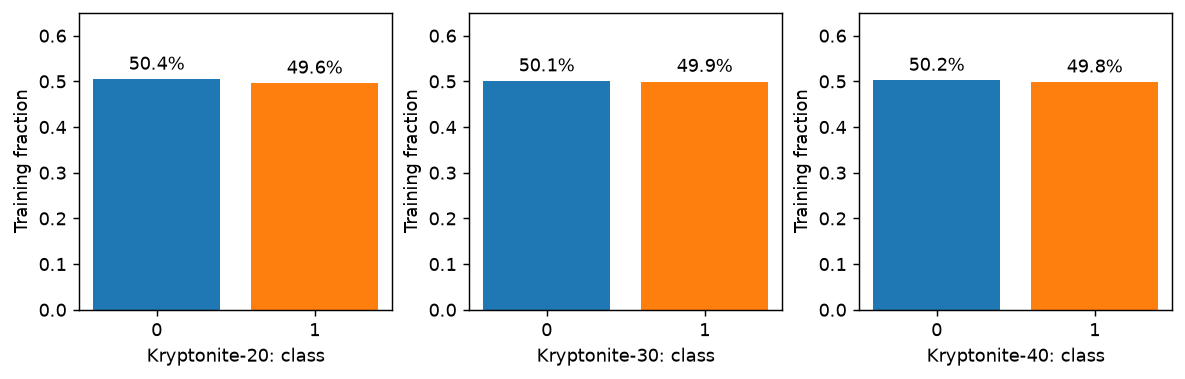

In [2]:
fig, axes=plt.subplots(1,3,figsize=(9,2.8),layout='constrained')
for ax,s in zip(axes,summaries):
    proportions=np.array(s['class_counts'])/s['training_rows']
    bars=ax.bar(['0','1'],proportions,color=['tab:blue','tab:orange'])
    ax.bar_label(bars,labels=[f'{p:.1%}' for p in proportions],padding=3)
    ax.set(xlabel=f"Kryptonite-{s['dataset']}: class",ylabel='Training fraction',ylim=(0,.65))
plt.show()

## Marginal scales and class distributions

Top: raw standard deviation for every feature, to assess scale differences. Bottom: the class-conditional distributions of **feature 1**, fixed in advance as an example. Overlapping marginal histograms cannot rule out useful joint or nonlinear information. Extreme observations are recorded descriptively, not deleted.

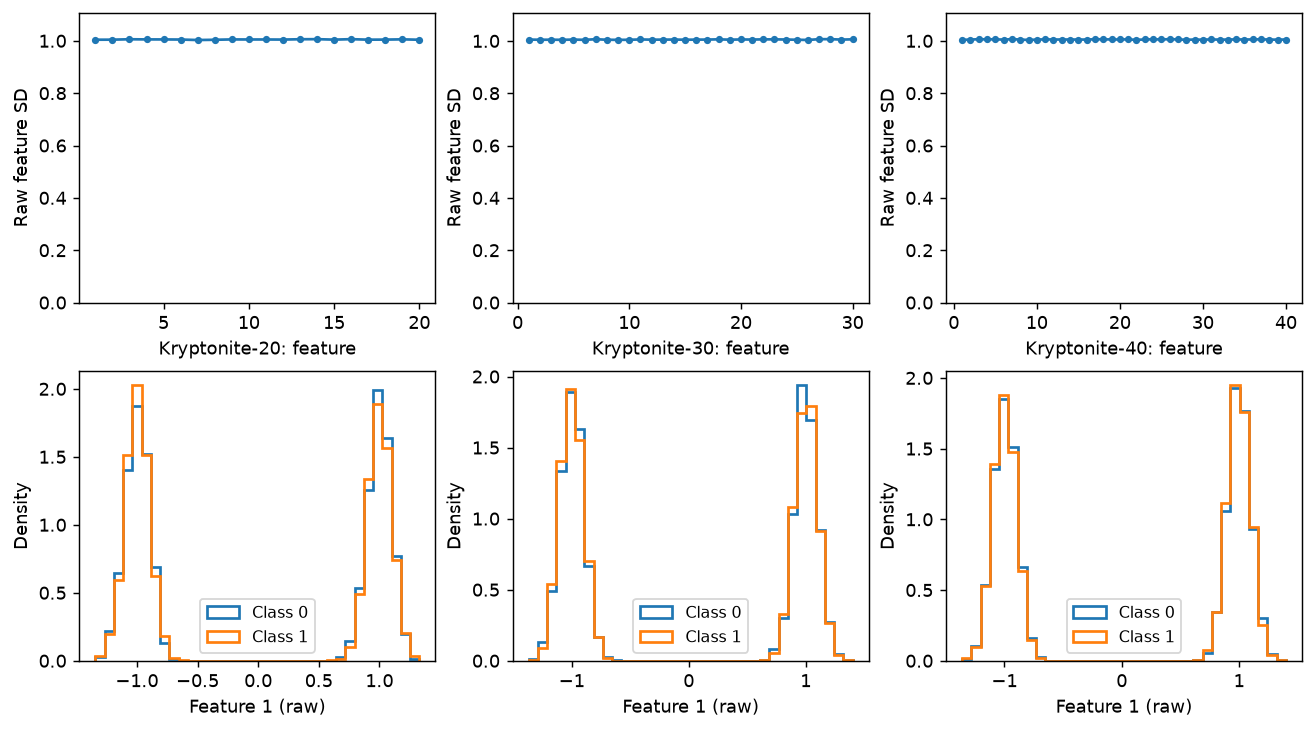

| Dataset | SD max / min | Max |class mean difference| / train SD |
| --- | --- | --- |
| 20 | 1.003 | 0.0583 |
| 30 | 1.003 | 0.0360 |
| 40 | 1.003 | 0.0330 |

In [3]:
fig,axes=plt.subplots(2,3,figsize=(10,5.5),layout='constrained')
for col,dataset in enumerate(data):
    d=data[dataset]; x,y=d['x'],d['y']
    axes[0,col].plot(np.arange(1,x.shape[1]+1),x.std(axis=0),'.-')
    axes[0,col].set(xlabel=f'Kryptonite-{dataset}: feature',ylabel='Raw feature SD',ylim=(0,1.1*x.std(axis=0).max()))
    bins=np.histogram_bin_edges(x[:,0],bins=35)
    for label,color in [(0,'tab:blue'),(1,'tab:orange')]:
        axes[1,col].hist(x[y==label,0],bins=bins,density=True,histtype='step',
                        linewidth=1.5,color=color,label=f'Class {label}')
    axes[1,col].set(xlabel='Feature 1 (raw)',ylabel='Density')
    axes[1,col].legend()
plt.show()
table(['Dataset','SD max / min','Max |class mean difference| / train SD'],
      [[s['dataset'],f"{s['feature_sd_ratio']:.3f}",
        f"{s['max_abs_standardized_class_mean_difference']:.4f}"] for s in summaries])

## Pairwise linear relationships

Pearson correlations describe pairwise linear dependence. Small correlations do **not** imply independence or absence of higher-order signal. Standardized class mean differences are descriptive statistics across all features, without significance claims or feature selection. The largest observed difference is subject to selection across many features.

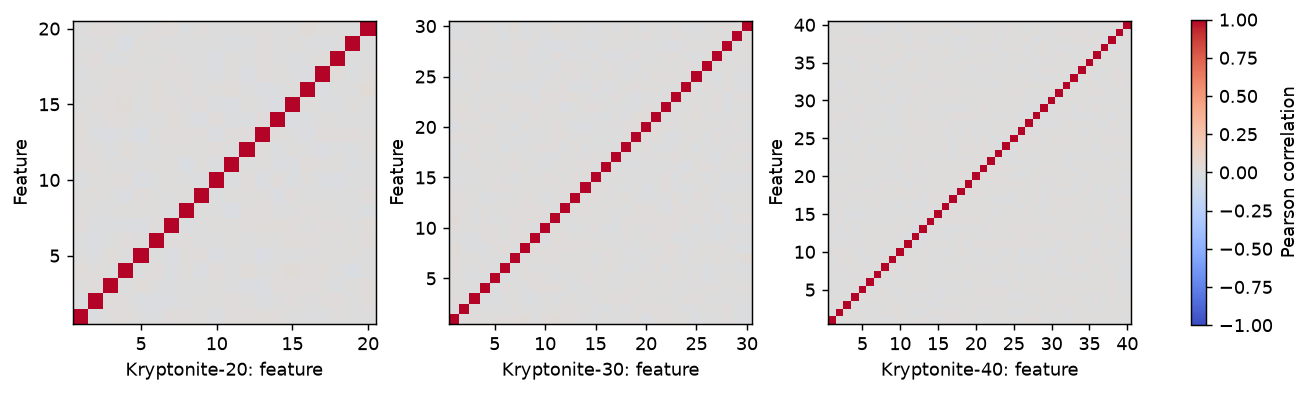

| Dataset | Median |r|, off diagonal | Max |r|, off diagonal |
| --- | --- | --- |
| 20 | 0.0073 | 0.0296 |
| 30 | 0.0064 | 0.0283 |
| 40 | 0.0047 | 0.0236 |

In [4]:
fig,axes=plt.subplots(1,3,figsize=(10,3.2),layout='constrained')
for ax,dataset in zip(axes,data):
    matrix=data[dataset]['corr']; dim=len(matrix)
    im=ax.imshow(matrix,vmin=-1,vmax=1,cmap='coolwarm',origin='lower',extent=(.5,dim+.5,.5,dim+.5))
    ticks=np.arange(5,dim+1,5)
    ax.set(xticks=ticks,yticks=ticks,xlabel=f'Kryptonite-{dataset}: feature',ylabel='Feature')
fig.colorbar(im,ax=axes,label='Pearson correlation',shrink=.8)
plt.show()
table(['Dataset','Median |r|, off diagonal','Max |r|, off diagonal'],
      [[s['dataset'],f"{s['median_abs_pairwise_correlation']:.4f}",
        f"{s['max_abs_pairwise_correlation']:.4f}"] for s in summaries])

## Linear dimensionality and two-dimensional projection

PCA is fitted to all standardized **training** rows. The upper panels measure retained variance, not predictive information. The lower panels show at most 500 deterministically sampled rows per class. PCA optimizes variance without labels, so an overlapping first-two-PC projection does not establish non-separability in the original space or prove that a kernel method is appropriate.

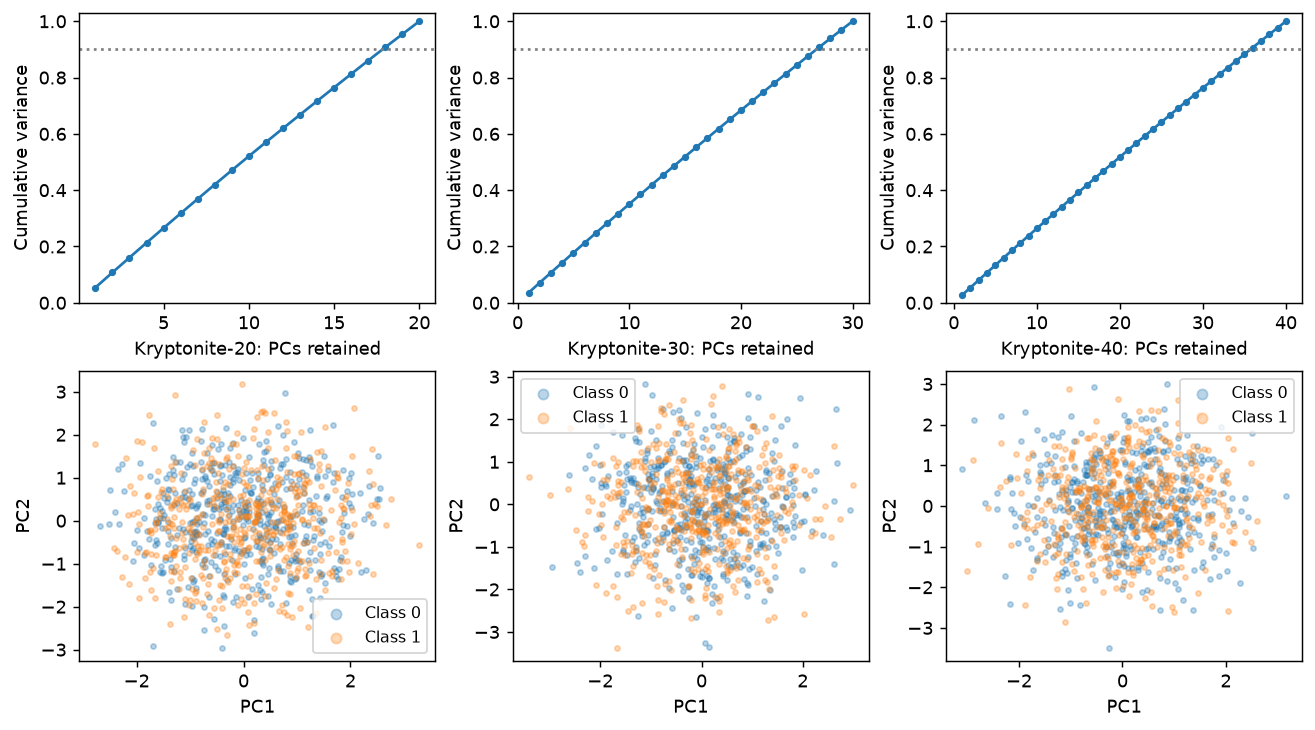

| Dataset | Variance in first 2 PCs | PCs for 90% variance |
| --- | --- | --- |
| 20 | 10.78% | 18 |
| 30 | 7.20% | 27 |
| 40 | 5.39% | 36 |

In [5]:
fig,axes=plt.subplots(2,3,figsize=(10,5.5),layout='constrained')
scatter_rows={}
for col,dataset in enumerate(data):
    d=data[dataset];dim=d['x'].shape[1]
    axes[0,col].plot(np.arange(1,dim+1),d['cumulative'],'.-')
    axes[0,col].axhline(.9,color='0.5',ls=':')
    axes[0,col].set(xlabel=f'Kryptonite-{dataset}: PCs retained',ylabel='Cumulative variance',ylim=(0,1.03))
    rng=np.random.default_rng(67); shown=[]
    for label,color in [(0,'tab:blue'),(1,'tab:orange')]:
        candidates=np.flatnonzero(d['y']==label)
        selected=rng.choice(candidates,size=min(500,len(candidates)),replace=False)
        shown.extend(d['indices'][selected].tolist())
        axes[1,col].scatter(d['pca'][selected,0],d['pca'][selected,1],
                           s=8,alpha=.3,color=color,label=f'Class {label}')
    scatter_rows[dataset]=shown
    axes[1,col].set(xlabel='PC1',ylabel='PC2');axes[1,col].legend(markerscale=2)
plt.show()
table(['Dataset','Variance in first 2 PCs','PCs for 90% variance'],
      [[s['dataset'],f"{s['pca_first2_variance_fraction']:.2%}",
        s['pca_components_for_90pct']] for s in summaries])

## Follow-up prompted by the marginal plots: two clusters near ±1

**Adaptive, post-hoc diagnostic:** after observing the feature-1 histograms, we check all features for concentration near -1 and +1. Report the RMS distance to the nearer of these two fixed centers and the fraction with |x| < 0.5. These centers and the zero sign threshold are descriptive choices prompted by the plots, not a fitted preprocessing change.

We also count repeated sign patterns and conflicting labels within those patterns, using training rows only. Distinct continuous rows can share a sign pattern. A lack of observed conflicts is not proof that signs completely determine labels, especially when almost all patterns occur once. No quantization, noise removal or new predictive model is adopted.

In [6]:
for s in summaries:
    d=data[s['dataset']];x,y=d['x'],d['y']
    signs=x>=0
    patterns,inverse,counts=np.unique(signs,axis=0,return_inverse=True,return_counts=True)
    positive=np.bincount(inverse,weights=y,minlength=len(patterns))
    rms=np.sqrt(np.mean((np.abs(x)-1)**2,axis=0))
    sign_summary={'diagnostic_status':'adaptive follow-up after marginal histogram inspection',
      'rms_distance_to_nearest_plus_minus_one_per_feature':rms.tolist(),
      'min_rms_distance':float(rms.min()),'max_rms_distance':float(rms.max()),
      'fraction_abs_x_below_half':float(np.mean(np.abs(x)<.5)),
      'sign_pattern_duplicate_excess_rows':int(len(x)-len(patterns)),
      'repeated_sign_patterns':int(np.sum(counts>1)),
      'sign_patterns_with_conflicting_labels':int(np.sum((positive>0)&(positive<counts))),
      'positive_sign_fraction_per_feature':np.mean(signs,axis=0).tolist()}
    s['sign_cluster_followup']=sign_summary
table(['Dataset','RMS distance to ±1, feature range','Fraction |x| < 0.5',
       'Repeated sign patterns','Conflicting repeated patterns'],
      [[s['dataset'],f"{s['sign_cluster_followup']['min_rms_distance']:.4f}–{s['sign_cluster_followup']['max_rms_distance']:.4f}",
        f"{s['sign_cluster_followup']['fraction_abs_x_below_half']:.6%}",
        s['sign_cluster_followup']['repeated_sign_patterns'],
        s['sign_cluster_followup']['sign_patterns_with_conflicting_labels']] for s in summaries])

| Dataset | RMS distance to ±1, feature range | Fraction |x| < 0.5 | Repeated sign patterns | Conflicting repeated patterns |
| --- | --- | --- | --- | --- |
| 20 | 0.0988–0.1016 | 0.000000% | 35 | 2 |
| 30 | 0.0987–0.1012 | 0.000000% | 0 | 0 |
| 40 | 0.0993–0.1009 | 0.000112% | 0 | 0 |

## Existing MLP training diagnostics

Reuse every predeclared run from the original width comparison; no new model is trained. Checkpoints were selected on validation accuracy, not lowest training loss or training accuracy. Therefore these selected-checkpoint gaps cannot isolate optimization difficulty. Loss increases after selection are descriptive indicators, not a proof of the cause of generalization error.

In [7]:
import csv
experiment=json.loads((root/'member_c/configs/p2_multiseed/manifest.json').read_text())
rows=collect(experiment)
groups, paired, candidates=aggregate(rows)
diagnostics=[]
for row in rows:
    run_dir=root/'member_c/results'/row['run_id']
    hp=run_dir/'history.csv'
    with hp.open() as f: history=list(csv.DictReader(f))
    best=next(r for r in history if int(r['epoch'])==row['best_epoch'])
    last=history[-1]
    diagnostics.append({'run_id':row['run_id'],'dataset':row['dataset'],
      'hidden_sizes':row['hidden_sizes'],'seed':row['seed'],
      'best_epoch':row['best_epoch'],'epochs_run':row['epochs_run'],
      'stop_reason':row['stop_reason'],
      'train_accuracy_at_selected':row['train_accuracy'],
      'validation_accuracy_at_selected':row['validation_accuracy'],
      'gap_percentage_points':row['gap_percentage_points'],
      'last_minus_selected_validation_BCE':float(last['validation_loss'])-float(best['validation_loss'])})
    for filename in ['summary.json','history.csv','config.json']:
        path=run_dir/filename;inputs[str(path.relative_to(root))]=digest(path)
table(['Dataset','Width','Mean train acc.','Mean val. acc.','Val. sample SD (pp)','Mean gap (pp)'],
 [[g['dataset'],g['hidden_sizes'],f"{g['mean_train_accuracy']:.2%}",
   f"{g['mean_validation_accuracy']:.2%}",f"{100*g['sample_std_validation_accuracy']:.2f}",
   f"{g['mean_gap_percentage_points']:.2f}"] for g in groups])
table(['Dataset','Wide - narrow, seed 42 (pp)','Seed 123 (pp)','Seed 2026 (pp)'],
 [[r['dataset'],f"{r['difference_seed_42_pp']:+.3f}",f"{r['difference_seed_123_pp']:+.3f}",
   f"{r['difference_seed_2026_pp']:+.3f}"] for r in paired])
print('Runs:',len(diagnostics),'Early stopped:',sum(r['stop_reason']=='early_stopping' for r in diagnostics))
print('Final validation BCE above selected-epoch BCE:',sum(r['last_minus_selected_validation_BCE']>0 for r in diagnostics))

| Dataset | Width | Mean train acc. | Mean val. acc. | Val. sample SD (pp) | Mean gap (pp) |
| --- | --- | --- | --- | --- | --- |
| 20 | 128x128 | 99.10% | 90.36% | 0.72 | 8.73 |
| 20 | 256x256 | 99.81% | 90.57% | 1.19 | 9.24 |
| 30 | 128x128 | 98.13% | 89.63% | 2.44 | 8.50 |
| 30 | 256x256 | 99.98% | 91.03% | 1.02 | 8.95 |
| 40 | 128x128 | 96.83% | 93.08% | 0.52 | 3.74 |
| 40 | 256x256 | 97.49% | 93.49% | 0.48 | 4.00 |

| Dataset | Wide - narrow, seed 42 (pp) | Seed 123 (pp) | Seed 2026 (pp) |
| --- | --- | --- | --- |
| 20 | +1.792 | -1.292 | +0.125 |
| 30 | +0.450 | +0.650 | +3.075 |
| 40 | -0.375 | +0.703 | +0.891 |

Runs: 18 Early stopped: 18
Final validation BCE above selected-epoch BCE: 17


## Recorded outputs and interpretation boundaries

The JSON below contains training-only summaries, all per-feature statistics, sampled row IDs and input hashes. It records existing development diagnostics separately. It does not contain test performance or hidden data. See `member_c/report/dataset_analysis_findings.md` for interpretations and `suggestion_decisions.md` for adopted/deferred advice. Re-execution deterministically replaces only this supplementary summary; original run artifacts remain immutable.

In [8]:
payload={'analysis_status':'post-evaluation supplementary exploratory analysis',
 'data_scope':'training rows of 20/30/40 only; existing train/validation logs',
 'no_new_training':True,'no_test_or_hidden_analysis':True,
 'input_sha256':dict(sorted(inputs.items())),
 'datasets':summaries,'pca_scatter_original_training_row_ids':scatter_rows,
 'existing_run_diagnostics':diagnostics,
 'existing_width_groups':groups,'paired_width_differences':paired}
out=root/'member_c/results/dataset_analysis';out.mkdir(parents=True,exist_ok=True)
(out/'summary.json').write_text(json.dumps(payload,indent=2,allow_nan=False)+'\n')
print('Saved numerical summary:',out/'summary.json')

Saved numerical summary: /Users/hardenzhao/Kryptonite_v3.0/member_c/results/dataset_analysis/summary.json
